# Insurance Customer Segmentation

**Business question:** Which customer groups exist in our policyholder base, and what should we do differently for each (retain, upsell, monitor)?

**Approach:** clean data, engineer insurance features, select k with several metrics, cluster with K-Means, validate against other methods and bootstrap stability, profile segments, and map each to an action.

> If `data/raw/auto_insurance_clv.csv` is missing, this notebook uses **synthetic** data. Replace it with the Kaggle file for real results.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import sys; sys.path.insert(0, "..")
import numpy as np, pandas as pd
from IPython.display import Image, display
from src import config, data_prep, features, clustering, profiling, visualize
pd.set_option("display.float_format", "{:,.2f}".format)
pd.set_option("display.width", 200)

## 1. Load and clean

In [2]:
source = data_prep.data_source()
print("Data source:", source)
df = features.add_features(data_prep.load_clean())
print(df.shape)
df[["monthly_premium","total_claim_amount","income","tenure_months","num_policies","clv"]].describe().T

Real data not found. Using SYNTHETIC data - do not quote these numbers on a resume.


Data source: synthetic
(6000, 27)


,count,mean,std,min,25%,50%,75%,max
monthly_premium,"6,000.00",103.83,32.74,61.00,75.58,96.66,131.39,205.53
total_claim_amount,"6,000.00",523.33,535.78,0.50,193.74,358.08,641.41,"4,950.52"
income,"6,000.00","45,909.62","31,493.69",0.00,"20,477.69","47,078.90","70,153.72","129,666.37"
tenure_months,"6,000.00",43.54,28.37,0.00,13.00,48.00,66.00,98.00
num_policies,"6,000.00",2.74,2.03,1.00,1.00,2.00,3.00,8.00
clv,"6,000.00","3,659.71","3,058.11",519.37,"1,301.17","2,325.17","5,515.29","24,456.52"


## 2. Explore

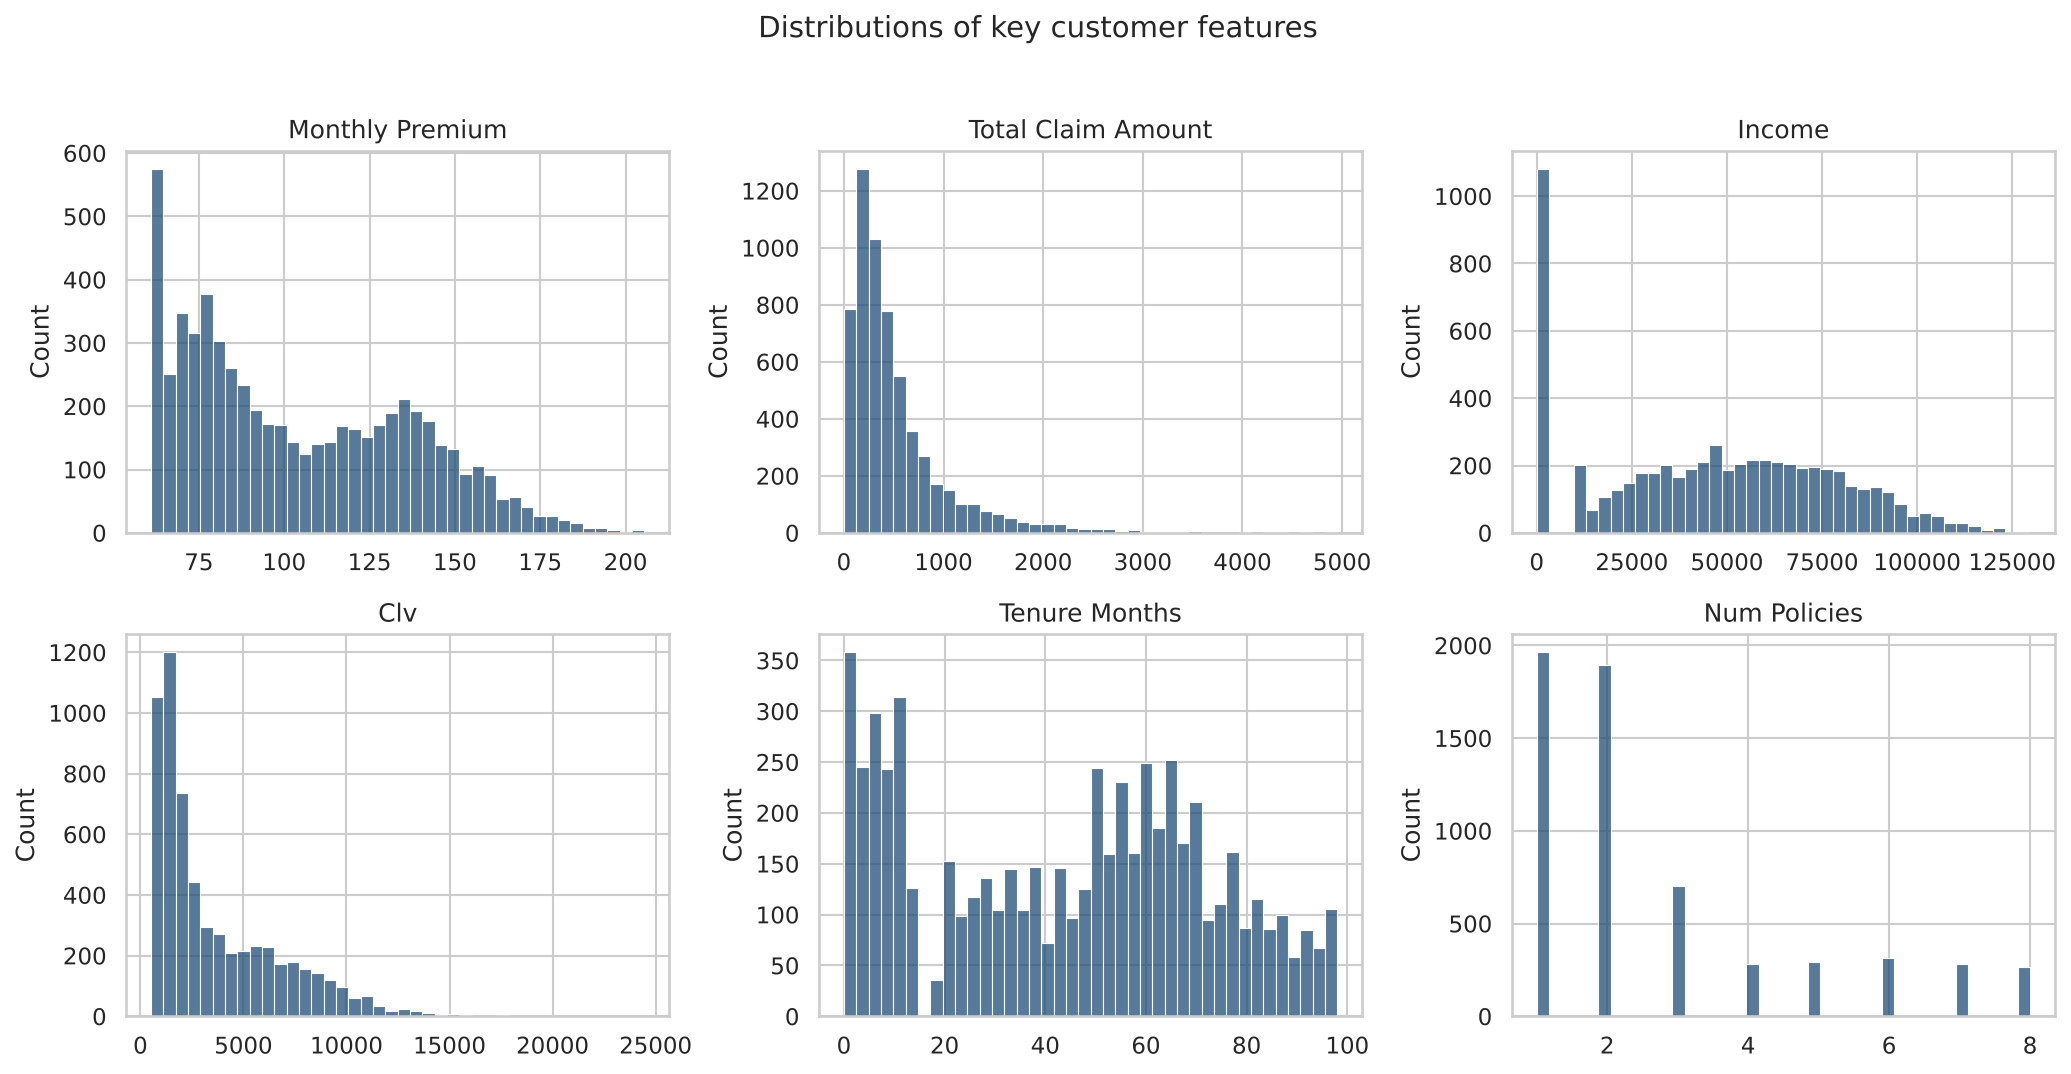

In [3]:
display(Image(filename=str(visualize.plot_distributions(df))))

Premium, claims, income and CLV are right-skewed, so they are log-transformed before scaling. Zero income is kept as a real value (unemployed or retired customers).

## 3. Feature engineering and scaling

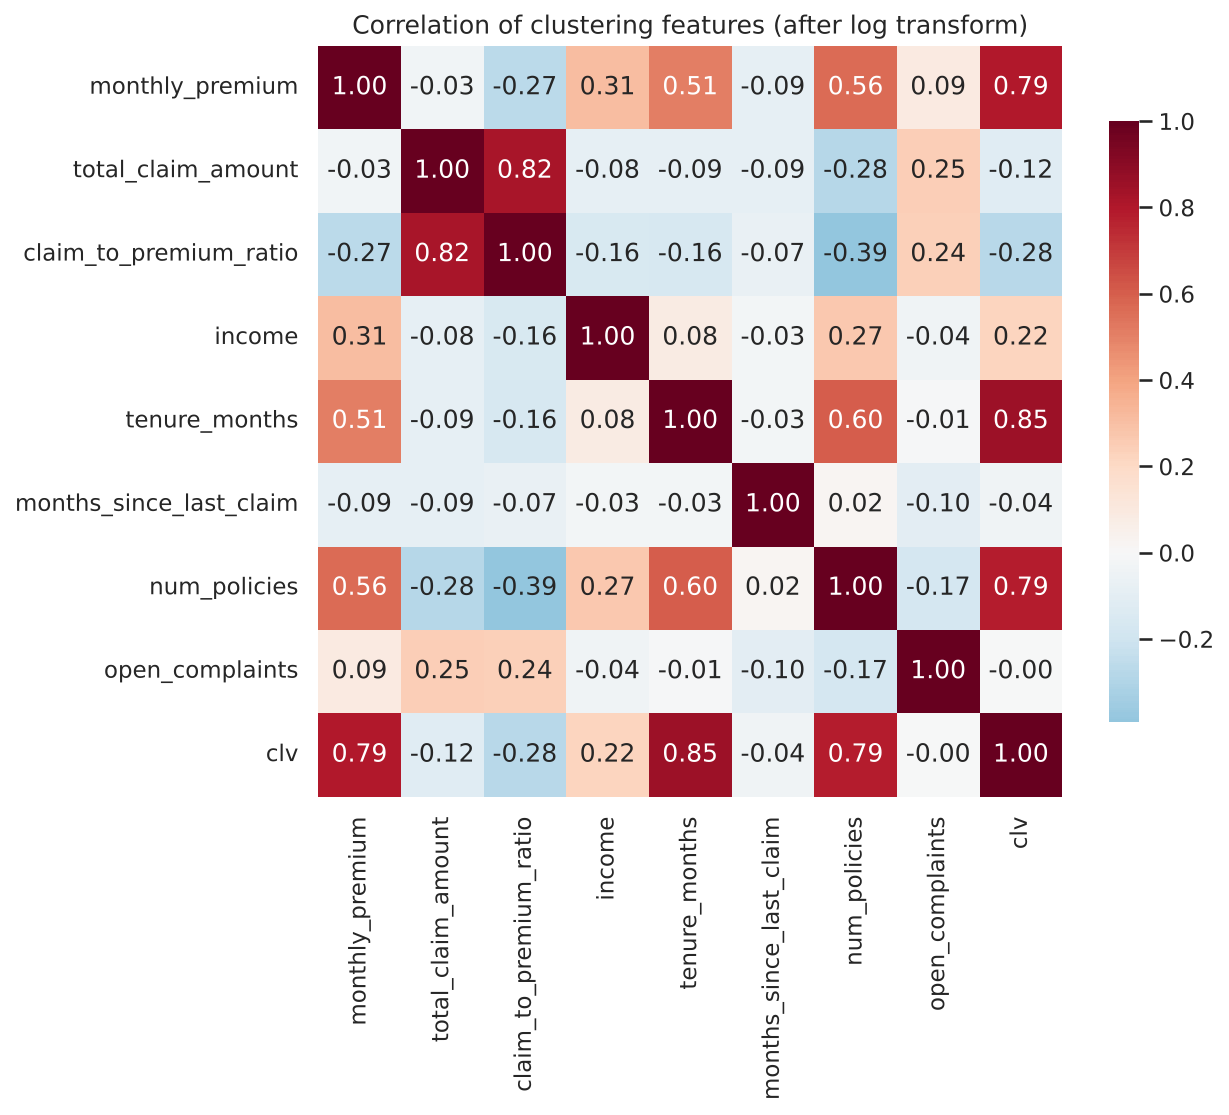

In [4]:
X = features.build_matrix(df)
Xs, scaler = features.scale(X)
display(Image(filename=str(visualize.plot_correlation(X))))

Premium and CLV are correlated, which is expected. K-Means is distance based, so scaling matters more than dropping correlated columns here.

## 4. Choose the number of clusters

,k,inertia,silhouette,davies_bouldin,calinski_harabasz,min_segment_share
0,2,"37,493.28",0.30,1.26,"2,640.67",0.32
1,3,"30,751.99",0.29,1.49,"2,266.82",0.22
2,4,"26,495.88",0.30,1.36,"2,074.72",0.16
3,5,"24,500.92",0.28,1.42,"1,804.50",0.12
4,6,"22,751.56",0.28,1.36,"1,646.51",0.08
5,7,"21,428.97",0.24,1.36,"1,518.18",0.06
6,8,"20,107.44",0.22,1.45,"1,442.85",0.06


Chosen k: 4


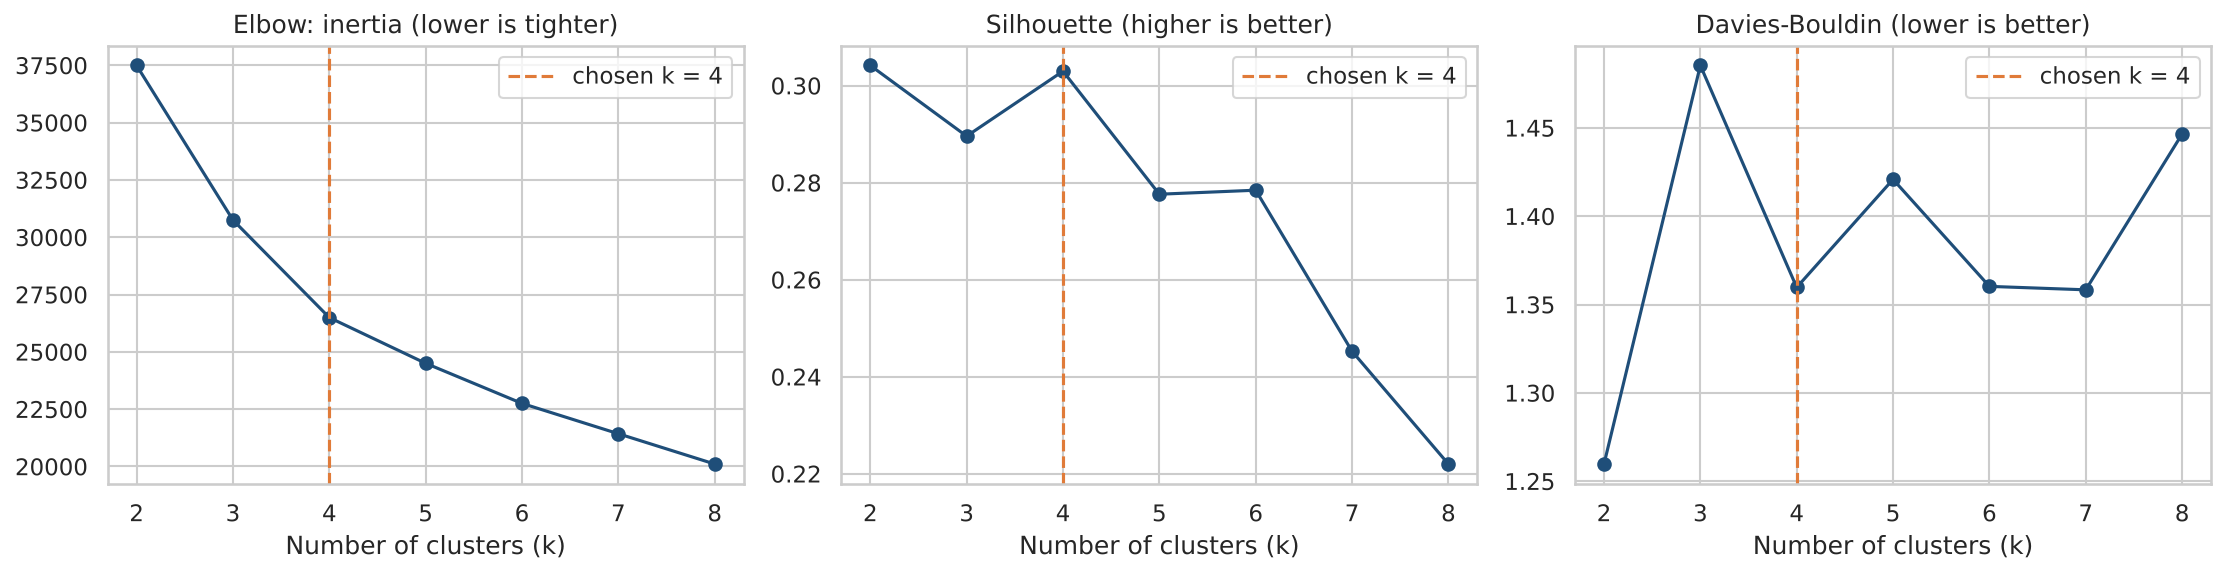

In [5]:
metrics = clustering.evaluate_k(Xs)
k = clustering.choose_k(metrics)
display(metrics.round(3))
print("Chosen k:", k)
display(Image(filename=str(visualize.plot_k_selection(metrics, k))))

k is chosen by the highest silhouette among values with k >= 3 and no segment under 5% of customers. k=2 is too coarse to act on.

## 5. Fit K-Means and profile segments

In [6]:
km = clustering.fit_kmeans(Xs, k)
prof = profiling.profile_segments(df, km.labels_)
names = prof["segment"].to_dict()
seg = pd.Series(km.labels_).map(names).values
prof.reset_index(drop=True)[["segment","customers","share_of_customers","share_of_premium","avg_monthly_premium","loss_ratio_proxy","tenure_months","clv","recommended_action"]]

,segment,customers,share_of_customers,share_of_premium,avg_monthly_premium,loss_ratio_proxy,tenure_months,clv,recommended_action
0,Loyal High-Value,1787,0.30,0.39,135.00,0.16,72.77,"7,529.99","Protect and reward: loyalty pricing, multi-pol..."
1,New Customers,2146,0.36,0.28,80.19,0.40,19.31,"1,358.44","Onboard and grow: welcome journey, early cross..."
2,High-Claim Risk Watch,1130,0.19,0.22,120.44,0.85,48.66,"3,446.79","Manage risk: underwriting review, repricing at..."
3,Low-Value Steady,937,0.16,0.12,78.53,0.52,37.12,"1,805.86",Serve efficiently: low-cost digital engagement...


## 6. Validate and explain the segmentation

In [7]:
stab = clustering.stability_score(Xs, k, km.labels_)
print("Bootstrap stability:", {k_: round(v, 3) if isinstance(v, float) else v for k_, v in stab.items()})

Bootstrap stability: {'mean_ari': 0.988, 'min_ari': 0.976, 'n_boot': 20}


A high Adjusted Rand Index across bootstrap refits means the segments are not an artefact of one sample.

In [8]:
explain = clustering.explain_segments(Xs, seg)
print(f"Decision tree (depth 3) cross-validated accuracy: {explain['tree_accuracy']:.1%}")
print(explain["rules"])

Decision tree (depth 3) cross-validated accuracy: 90.5%
|--- num_policies <= -0.12
|   |--- income <= -1.02
|   |   |--- monthly_premium <= 0.23
|   |   |   |--- class: Low-Value Steady
|   |   |--- monthly_premium >  0.23
|   |   |   |--- class: High-Claim Risk Watch
|   |--- income >  -1.02
|   |   |--- clv <= -0.21
|   |   |   |--- class: New Customers
|   |   |--- clv >  -0.21
|   |   |   |--- class: High-Claim Risk Watch
|--- num_policies >  -0.12
|   |--- claim_to_premium_ratio <= 0.18
|   |   |--- open_complaints <= 1.62
|   |   |   |--- class: Loyal High-Value
|   |   |--- open_complaints >  1.62
|   |   |   |--- class: High-Claim Risk Watch
|   |--- claim_to_premium_ratio >  0.18
|   |   |--- num_policies <= 0.37
|   |   |   |--- class: High-Claim Risk Watch
|   |   |--- num_policies >  0.37
|   |   |   |--- class: Loyal High-Value



A shallow tree can predict the segment from the features, so the segments are separable and describable in plain rules. Thresholds are z-scores (0 = average customer).

,importance
income,0.26
clv,0.18
num_policies,0.16
monthly_premium,0.10
total_claim_amount,0.09
tenure_months,0.07
claim_to_premium_ratio,0.07
open_complaints,0.05
months_since_last_claim,0.01


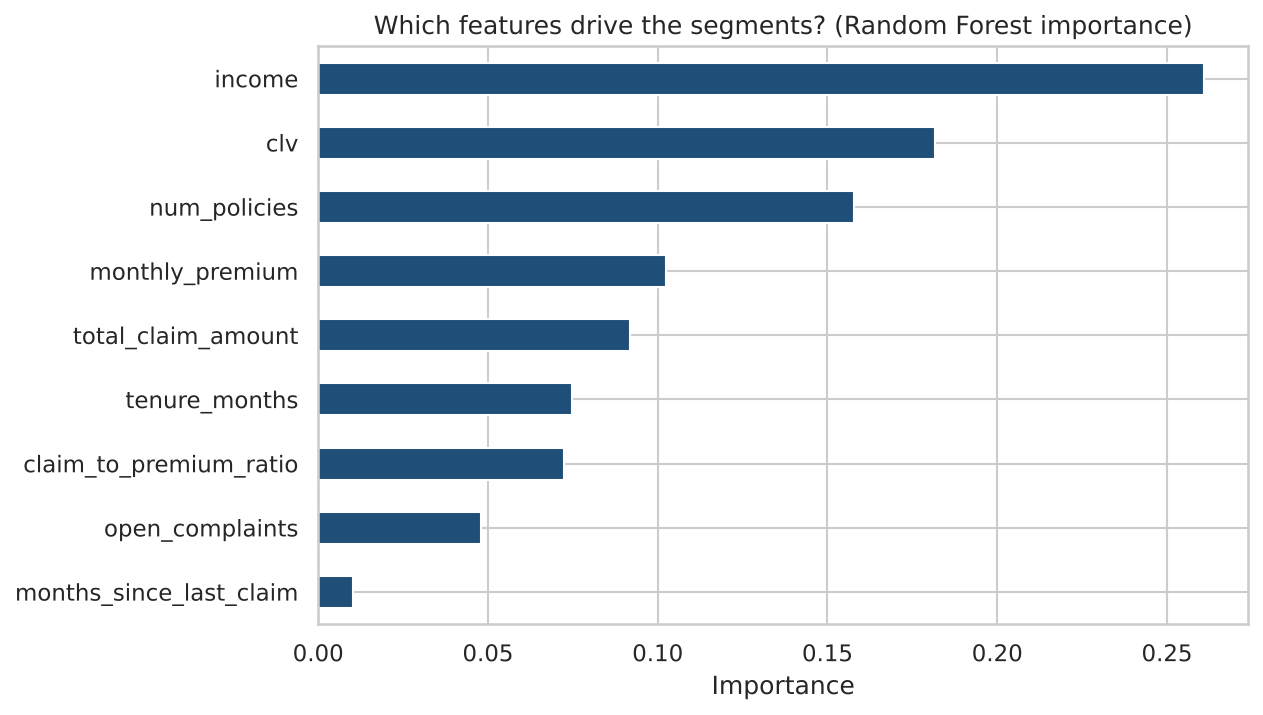

In [9]:
display(explain["importance"].round(3).to_frame("importance"))
display(Image(filename=str(visualize.plot_feature_importance(explain["importance"]))))

Random Forest importance shows which features drive the segmentation most.

## 7. Visualise the segments

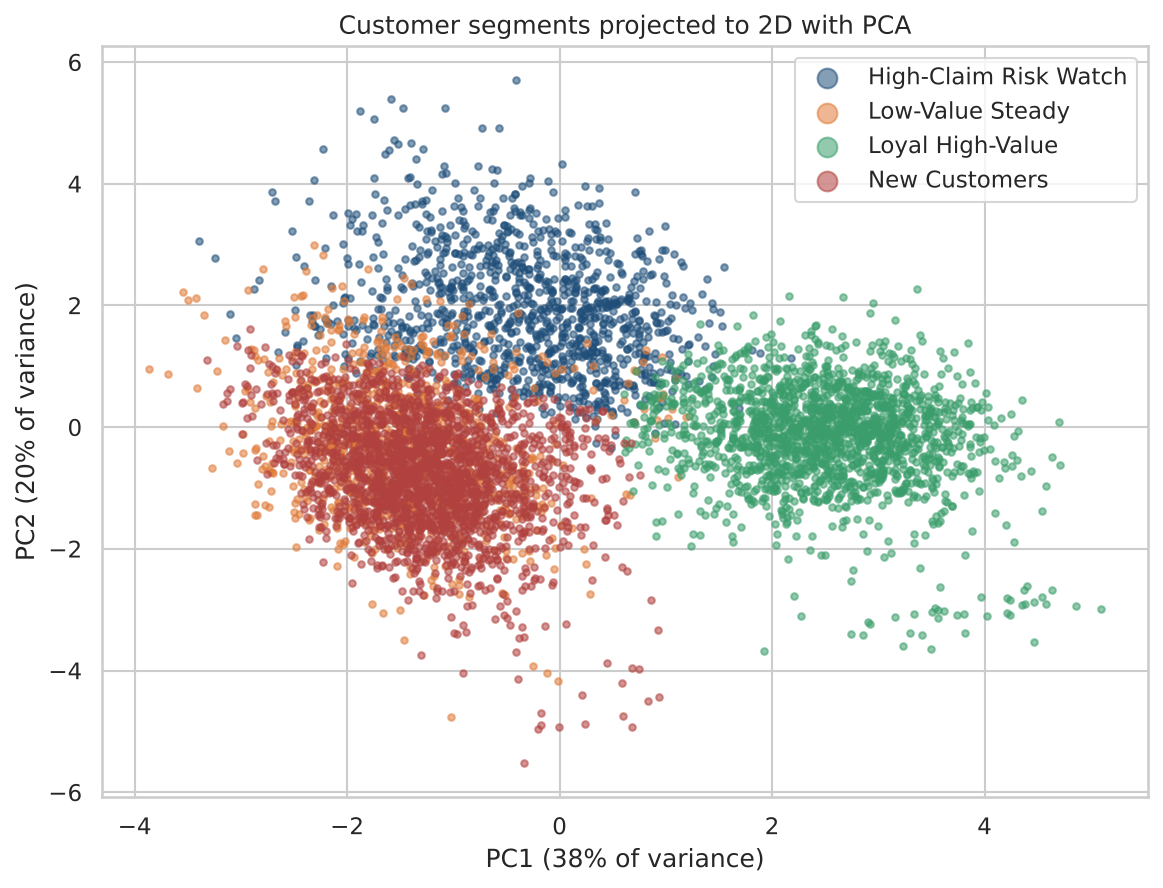

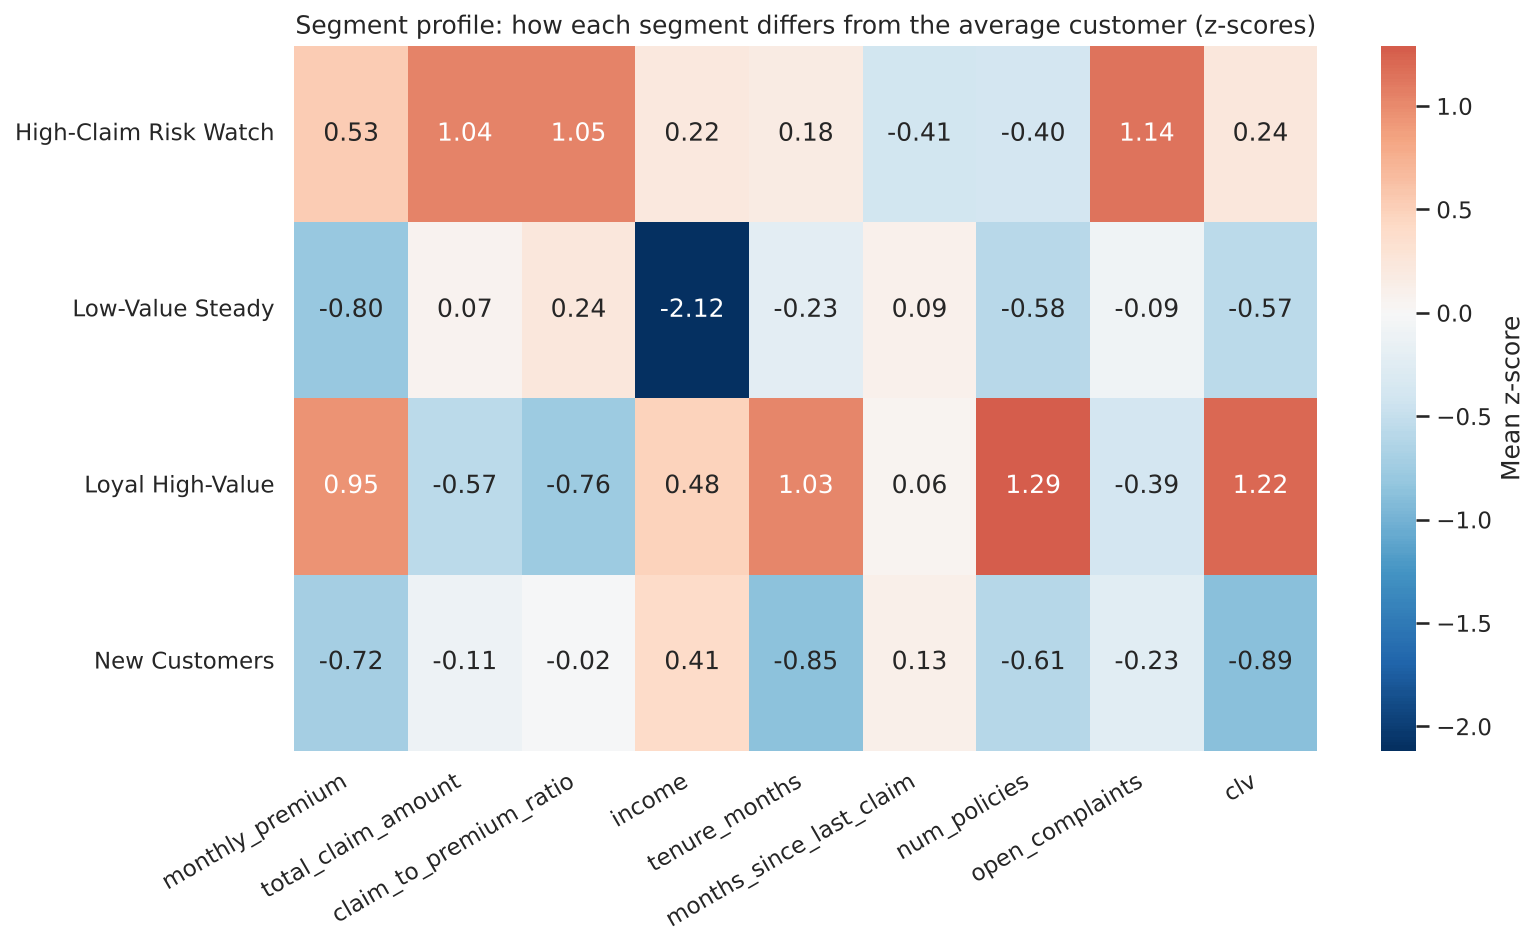

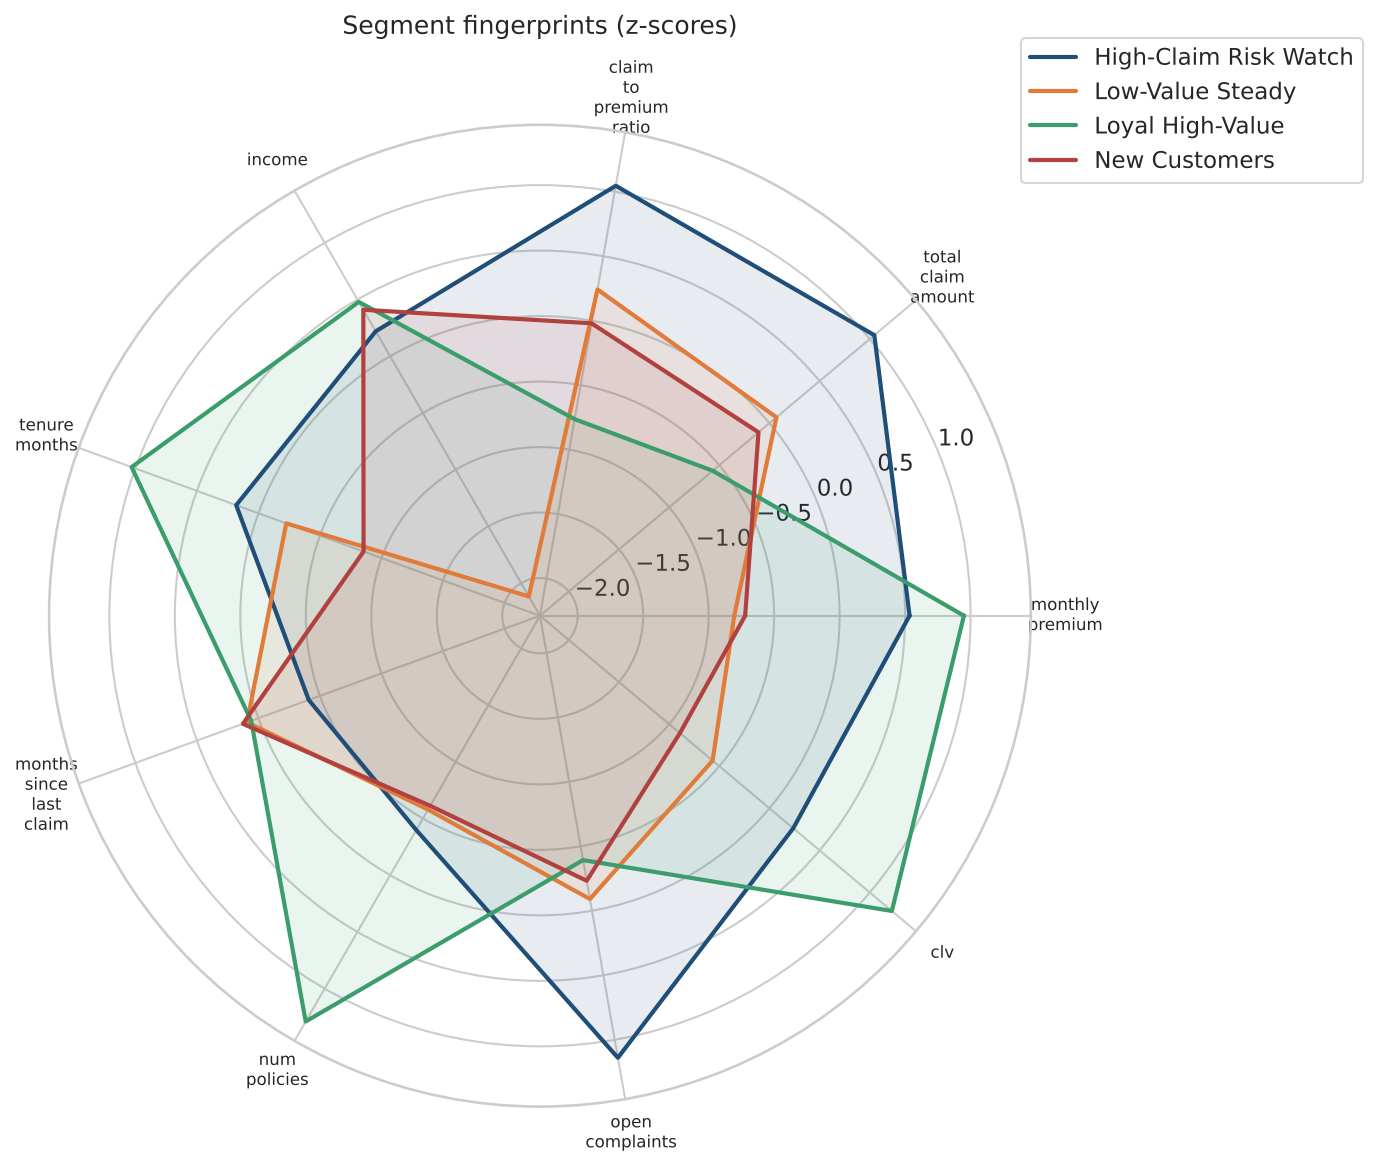

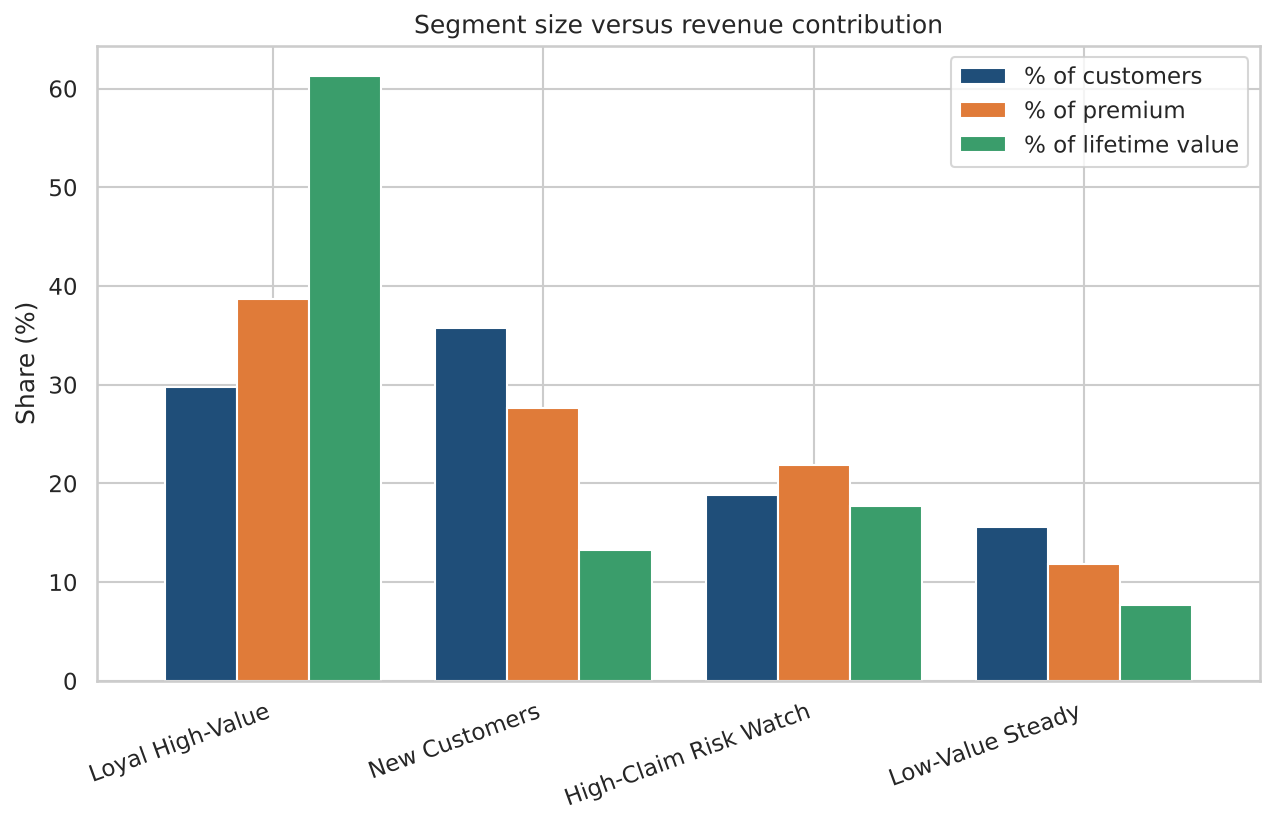

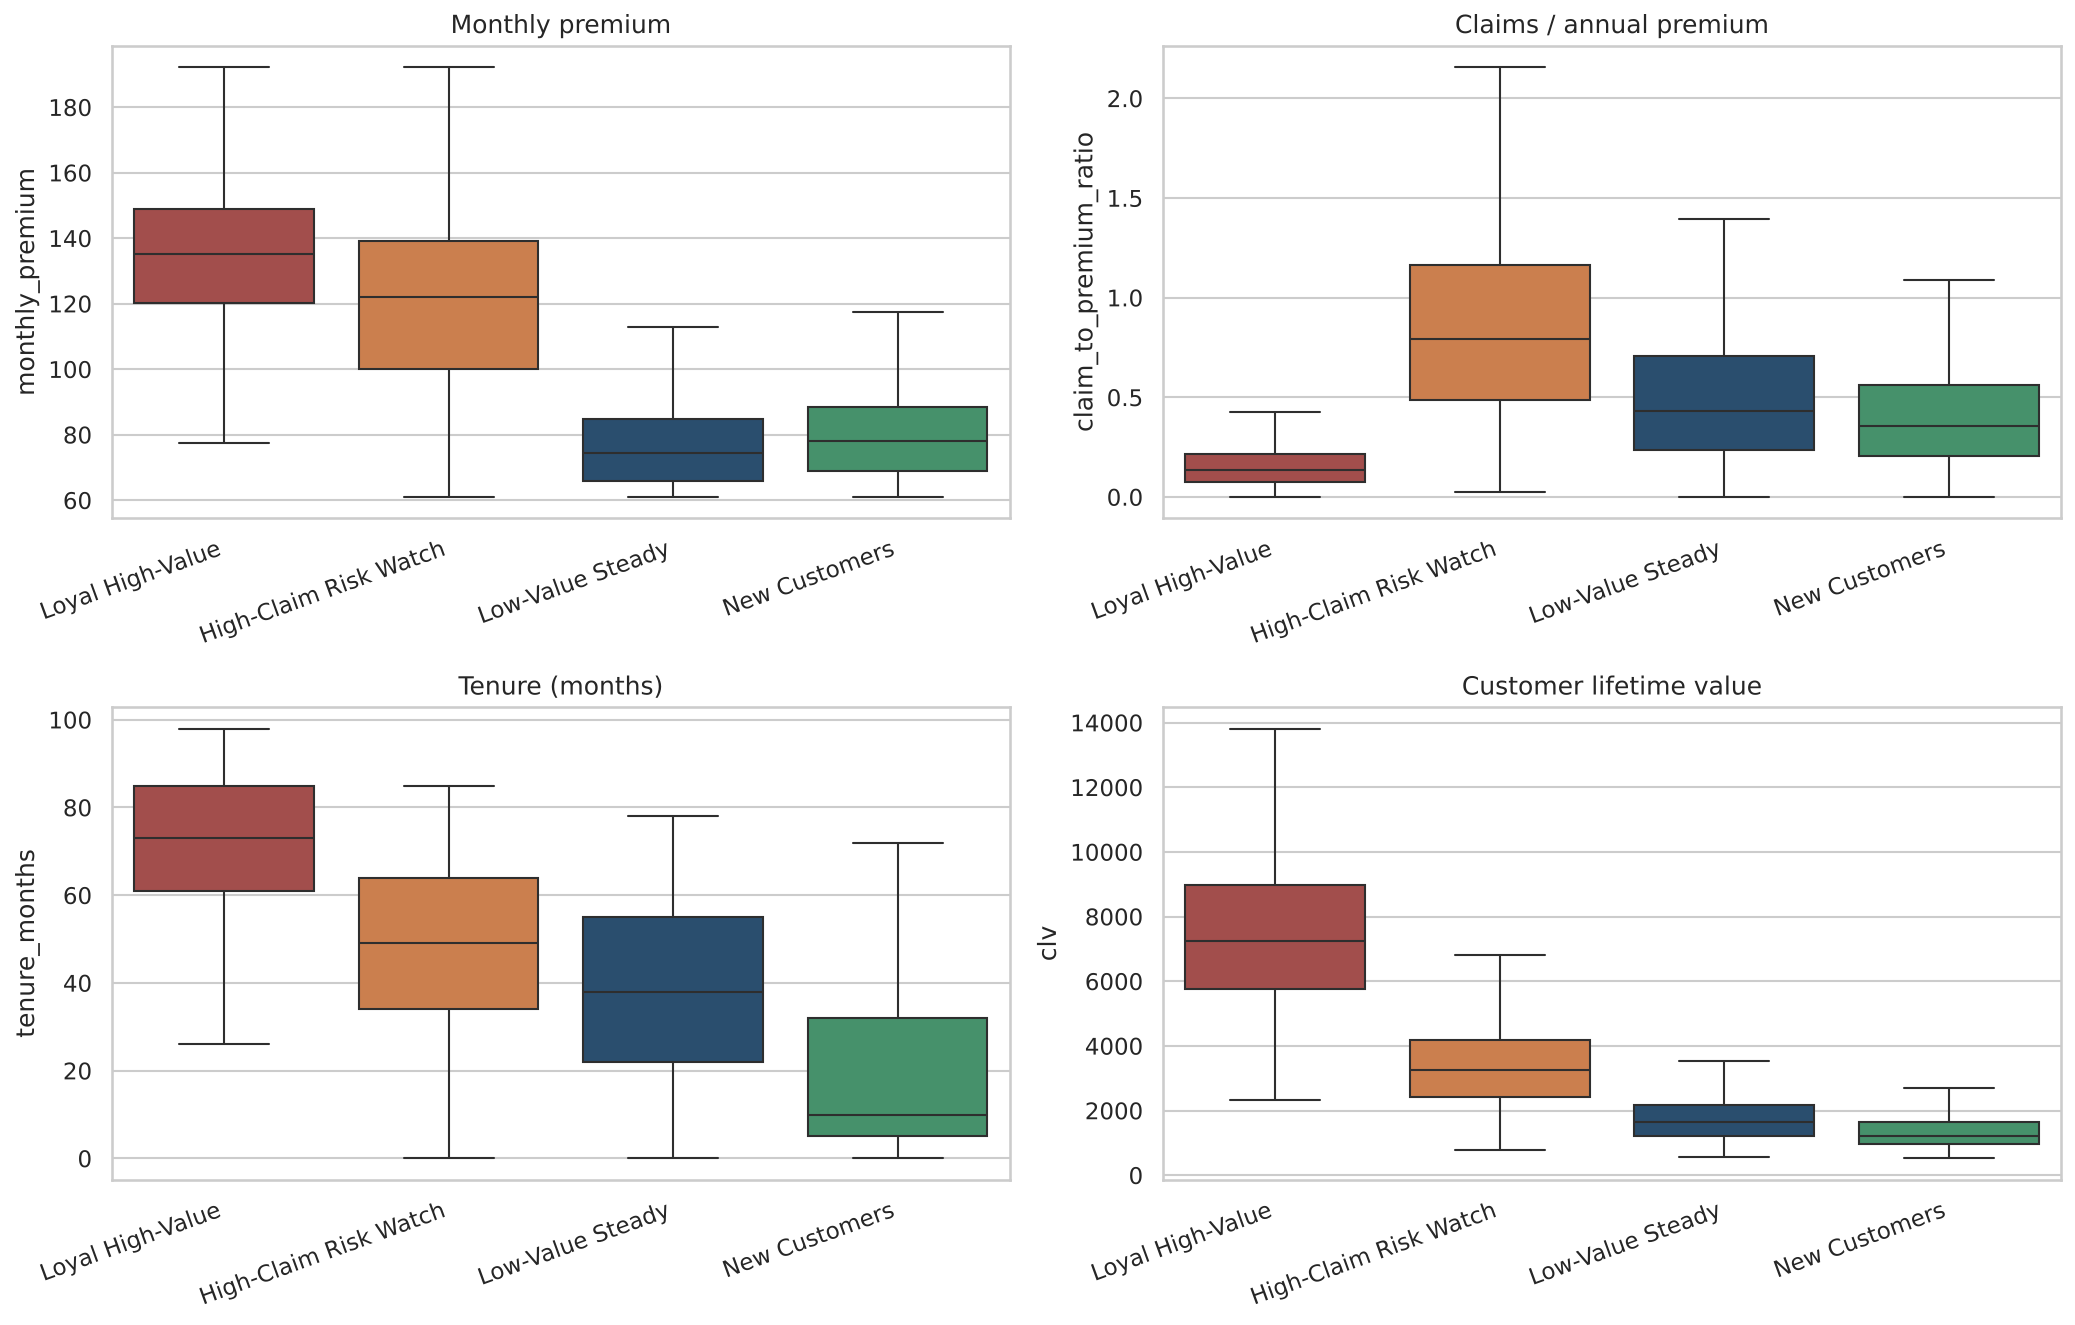

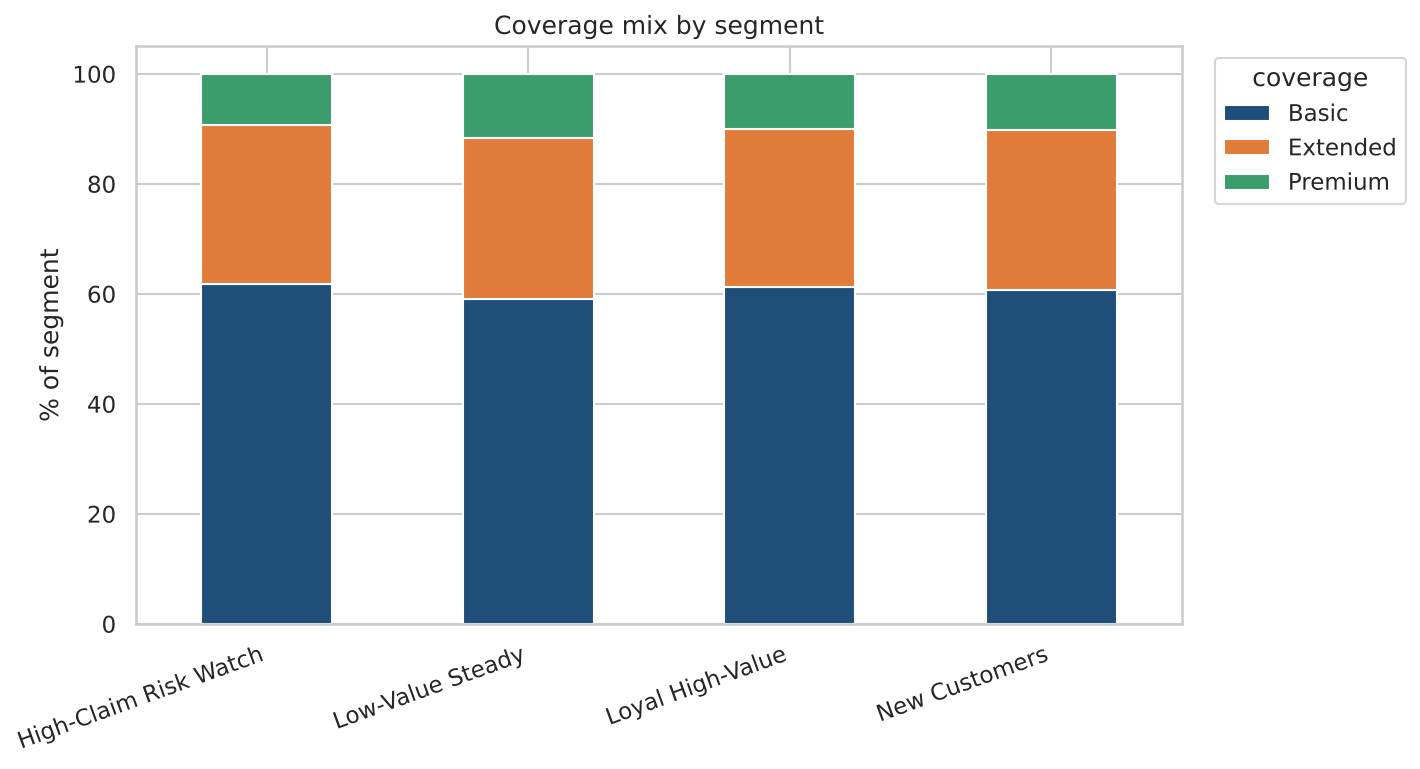

In [10]:
for fn in (visualize.plot_pca, visualize.plot_profile_heatmap, visualize.plot_radar):
    display(Image(filename=str(fn(Xs, seg))))
display(Image(filename=str(visualize.plot_size_vs_value(prof))))
display(Image(filename=str(visualize.plot_boxplots(df, seg))))
display(Image(filename=str(visualize.plot_categorical_mix(df, seg, "coverage"))))

## 8. Business recommendations

In [11]:
for r in prof.itertuples():
    print(f"{r.segment:<24} {r.share_of_customers:5.1%} of customers | {r.share_of_premium:5.1%} of premium\n    -> {r.recommended_action}\n")

Loyal High-Value         29.8% of customers | 38.7% of premium
    -> Protect and reward: loyalty pricing, multi-policy bundles, proactive renewal outreach.

New Customers            35.8% of customers | 27.6% of premium
    -> Onboard and grow: welcome journey, early cross-sell, first-year engagement to improve retention.

High-Claim Risk Watch    18.8% of customers | 21.8% of premium
    -> Manage risk: underwriting review, repricing at renewal, claims-prevention programmes.

Low-Value Steady         15.6% of customers | 11.8% of premium
    -> Serve efficiently: low-cost digital engagement, selective upsell, avoid heavy discounting.



## 9. Score new customers with the saved model
Run `python run_pipeline.py` first so `models/` exists.

In [12]:
from src.generate_data import generate
from src.predict import assign_segments
new = assign_segments(generate(n=300, seed=7))
new["segment"].value_counts()

segment
New Customers            111
Loyal High-Value          89
High-Claim Risk Watch     51
Low-Value Steady          49
Name: count, dtype: int64

## 10. Limitations and next steps
- Segments are descriptive; validate them with a business test (for example A/B test retention offers per segment).
- Join the churn model's predicted probability per segment to prioritise outreach.
- Add categorical features (coverage, vehicle class) with K-Prototypes or Gower distance as an extension.
- Re-run quarterly and monitor segment drift.